# ANÁLISE P4 | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para responder à pergunta P4.
___

### 0 | Importações
___

In [2]:
# Manipulação de dados:
import pandas as pd
import numpy as np             

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio

pio.renderers.default='png'

In [3]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### P4 | Explorando dados da evolução da arrecadação dos filmes
___


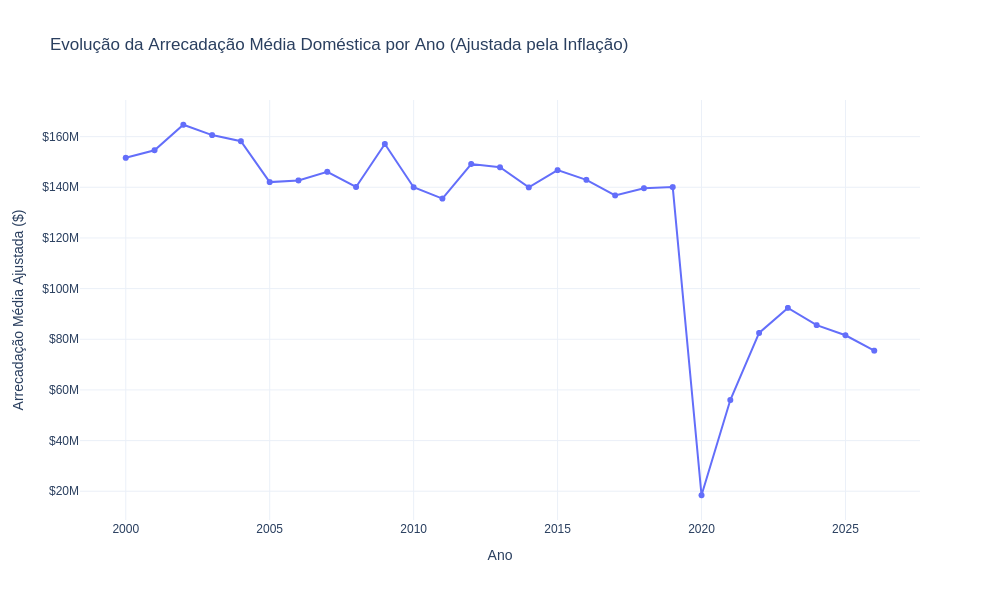

In [4]:
df_anual = df.groupby('year')['domestic_bo'].mean().reset_index()

# Opcional: Se quiser remover eventuais anos nulos ou 0 que possam corromper a linha
#df_anual = df_anual.dropna()

# 3. Cria o gráfico de linhas com Plotly Express
fig = px.line(
    df_anual,
    x='year',                  # Eixo X: Anos
    y='domestic_bo',           # Eixo Y: Arrecadação média
    markers=True,              # Adiciona pontos visíveis em cada ano (facilita o hover)
    title='Evolução da Arrecadação Média Doméstica por Ano (Ajustada pela Inflação)',
    labels={
        'year': 'Ano de Lançamento',
        'domestic_bo': 'Média de Bilheteria Doméstica ($)'
    }
)

# 4. Ajustes visuais para formatar o layout e os eixos
fig.update_layout(
    xaxis_title='Ano',
    yaxis_title='Arrecadação Média Ajustada ($)',
    width=1000,
    height=600,
    template='plotly_white',
    hovermode='x unified'      # Une o tooltip de hover para facilitar a leitura por ano
)

# Formata o eixo Y para exibir os valores de forma amigável (opcional)
fig.update_yaxes(tickprefix='$', separatethousands=True)

# Exibe o gráfico interativo
fig.show()

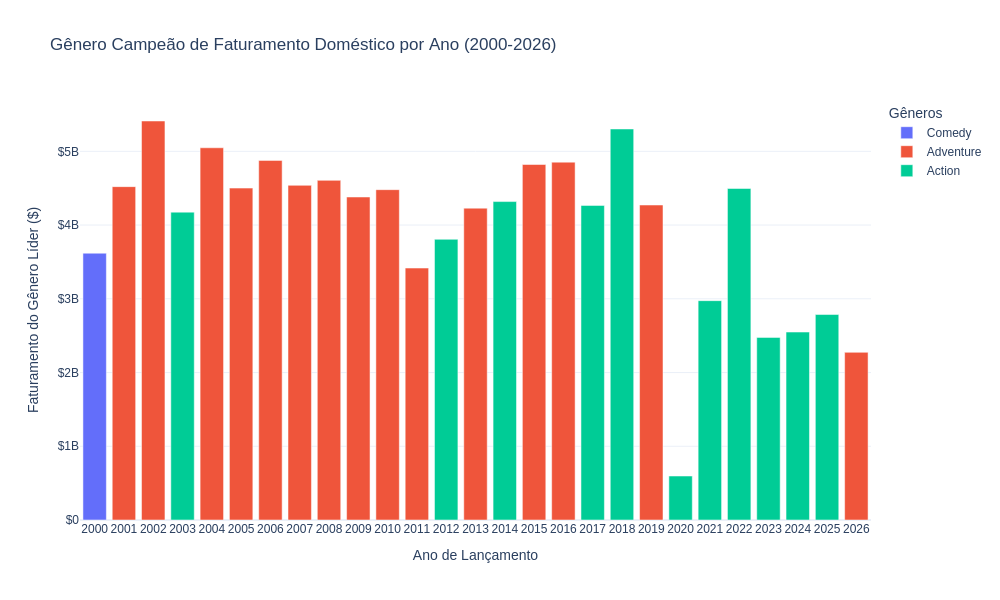

In [6]:
df_fat_ano = df.groupby(['year', 'genre'])['domestic_bo'].sum().reset_index()

# 3. Filtra apenas o gênero com o MAIOR faturamento para cada ano
idx_max = df_fat_ano.groupby('year')['domestic_bo'].idxmax()
df_top_genre = df_fat_ano.loc[idx_max].reset_index(drop=True)

# 4. Ordena estritamente por ano e converte para string (garante a ordem cronológica visual)
df_top_genre = df_top_genre.sort_values('year').reset_index(drop=True)
df_top_genre['year'] = df_top_genre['year'].astype(str)

# 5. Cria o gráfico de barras travando a ordem exata das categorias
fig = px.bar(
    df_top_genre,
    x='year',
    y='domestic_bo',
    color='genre',              # Cada gênero campeão ganha uma cor distinta na legenda
    title='Gênero Campeão de Faturamento Doméstico por Ano (2000-2026)',
    labels={
        'year': 'Ano de Lançamento', 
        'domestic_bo': 'Faturamento do Gênero Líder ($)',
        'genre': 'Gêneros'
    },
    category_orders={'year': df_top_genre['year'].tolist()} # Força a ordem exata da lista
)

# 6. Ajustes visuais
fig.update_layout(
    width=1000, 
    height=600, 
    template='plotly_white'
)
fig.update_yaxes(tickprefix='$', separatethousands=True)

fig.show()

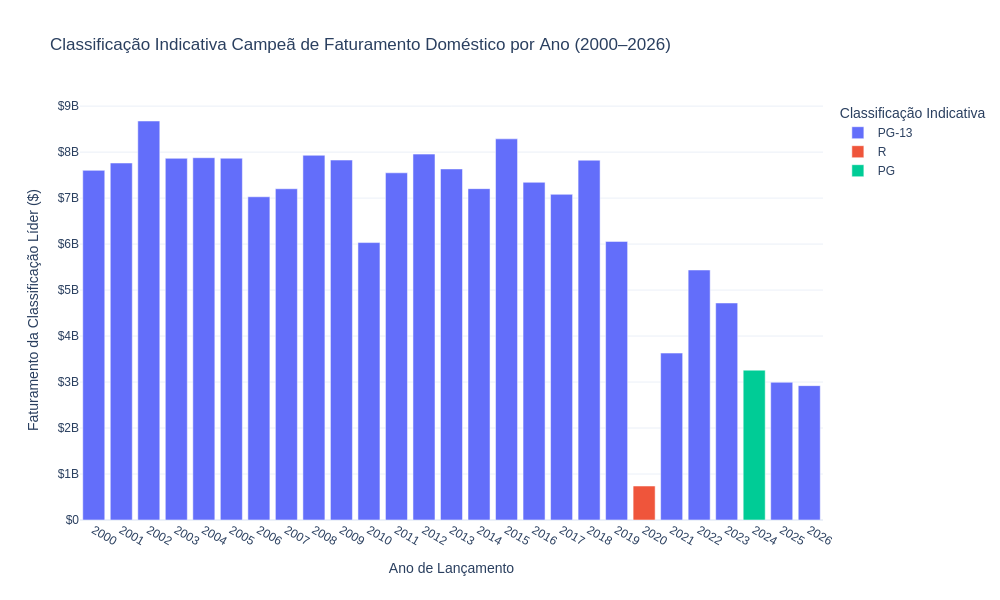

In [7]:
candidatos_rating = ['rating', 'mpaa_rating', 'classificacao', 'content_rating']
col_rating = next((c for c in candidatos_rating if c in df.columns), None)

if col_rating:
    # 2. Agrupa por ano e classificação somando o faturamento total ajustado
    df_fat_rating_ano = (
        df.groupby(['year', col_rating], dropna=False)['domestic_bo']
        .sum()
        .reset_index()
    )
    df_fat_rating_ano[col_rating] = df_fat_rating_ano[col_rating].fillna('Não Informado').astype(str)

    # 3. Filtra apenas a classificação com o MAIOR faturamento para cada ano
    idx_max_rating = df_fat_rating_ano.groupby('year')['domestic_bo'].idxmax()
    df_top_rating = df_fat_rating_ano.loc[idx_max_rating].reset_index(drop=True)

    # 4. Ordena estritamente por ano e converte para string
    df_top_rating = df_top_rating.sort_values('year').reset_index(drop=True)
    df_top_rating['year'] = df_top_rating['year'].astype(str)

    # 5. Cria o gráfico de barras travando a ordem exata dos anos
    fig_rating_ano = px.bar(
        df_top_rating,
        x='year',
        y='domestic_bo',
        color=col_rating,
        title='Classificação Indicativa Campeã de Faturamento Doméstico por Ano (2000–2026)',
        labels={
            'year': 'Ano de Lançamento',
            'domestic_bo': 'Faturamento da Classificação Líder ($)',
            col_rating: 'Classificação Indicativa'
        },
        category_orders={'year': df_top_rating['year'].tolist()}
    )

    # 6. Ajustes visuais
    fig_rating_ano.update_layout(
        width=1000,
        height=600,
        template='plotly_white'
    )
    fig_rating_ano.update_yaxes(tickprefix='$', separatethousands=True)

    fig_rating_ano.show()
else:
    print("Aviso: Coluna de classificação indicativa não encontrada no DataFrame.")

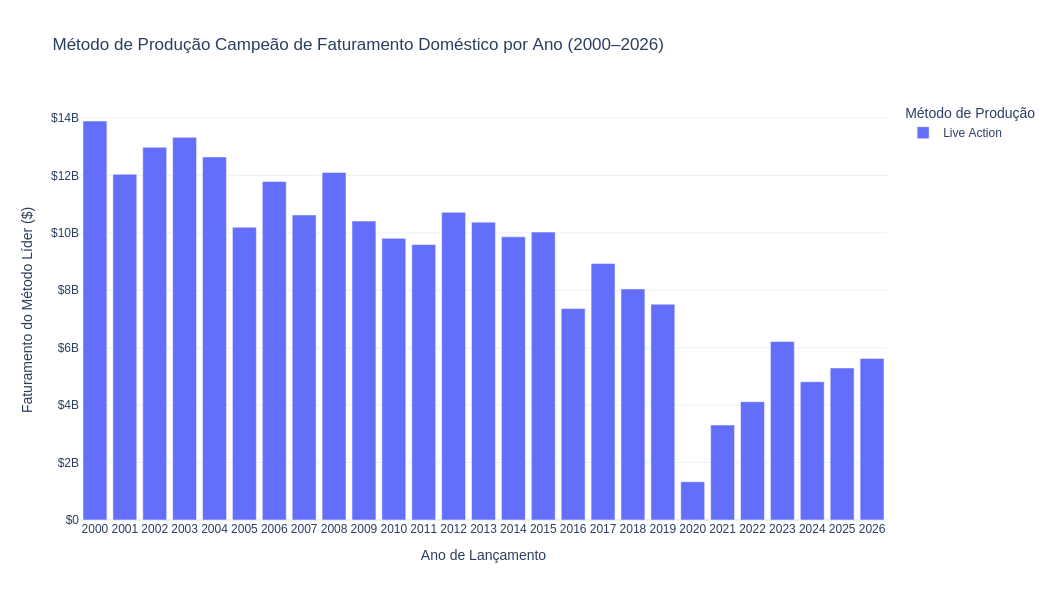

In [8]:
candidatos_producao = [
    'producao', 'production_method', 'production',
    'creative_type', 'tipo_producao', 'source'
]
col_producao = next((c for c in candidatos_producao if c in df.columns), None)

if col_producao:
    # 2. Agrupa por ano e método de produção somando o faturamento total ajustado
    df_fat_prod_ano = (
        df.groupby(['year', col_producao], dropna=False)['domestic_bo']
        .sum()
        .reset_index()
    )
    df_fat_prod_ano[col_producao] = df_fat_prod_ano[col_producao].fillna('Não Informado').astype(str)

    # 3. Filtra apenas o método de produção com o MAIOR faturamento para cada ano
    idx_max_prod = df_fat_prod_ano.groupby('year')['domestic_bo'].idxmax()
    df_top_prod = df_fat_prod_ano.loc[idx_max_prod].reset_index(drop=True)

    # 4. Ordena estritamente por ano e converte para string
    df_top_prod = df_top_prod.sort_values('year').reset_index(drop=True)
    df_top_prod['year'] = df_top_prod['year'].astype(str)

    # 5. Cria o gráfico de barras travando a ordem exata dos anos
    fig_prod_ano = px.bar(
        df_top_prod,
        x='year',
        y='domestic_bo',
        color=col_producao,
        title='Método de Produção Campeão de Faturamento Doméstico por Ano (2000–2026)',
        labels={
            'year': 'Ano de Lançamento',
            'domestic_bo': 'Faturamento do Método Líder ($)',
            col_producao: 'Método de Produção'
        },
        category_orders={'year': df_top_prod['year'].tolist()}
    )

    # 6. Ajustes visuais
    fig_prod_ano.update_layout(
        width=1050,
        height=600,
        template='plotly_white'
    )
    fig_prod_ano.update_yaxes(tickprefix='$', separatethousands=True)

    fig_prod_ano.show()
else:
    print("Aviso: Coluna de método de produção não encontrada no DataFrame.")